# COMPAYL Tutorial: From Single Modalities to Fusion — and What Happens When RNA Is Missing

This notebook is designed for a **live tutorial**, not for model development. The models are already trained; you do **not** train models or edit preprocessing code.

The learning sequence is:

**Clinical → Pathology → RNA → Concatenation → Gated fusion → Outcome → Missing RNA → Full comparison**

### What you will learn

1. **Modalities disagree.** Clinical data, pathology and RNA can each tell a different story about the same patient — that disagreement is what fusion has to resolve.
2. **Fusion changes the model's behaviour.** Concatenation gives the survival head everything; gated fusion adds per-patient scaling you can inspect — but a gate is not an importance score.
3. **Score against outcomes, not intuition.** "Which model is better" is answered by counting correctly ordered pairs against what actually happened, not by which ranking looks more convincing.
4. **Evaluate for deployment.** Test every model under the data you will actually have, including a missing modality, and notice that robustness comes from training, not from architecture alone.

### How we'll decide which model "wins"

Once outcomes are revealed (Step 3), every model is scored the same way: for each pair of patients scored by the same trained model, if one of them progressed before the other's follow-up ended, the model "wins" that pair when it gave the sooner-progressing patient the higher predicted risk. The score is correctly-ordered pairs out of every pair we can judge this way — a small, hands-on version of the concordance index (C-index) used to evaluate Cox models. Higher is better.

With only 10 patients this is a live demonstration of *how* to compare models, not a final verdict. But it is exactly the right question to ask of any multimodal model: not "which one looks most sophisticated," but "which one gets the ordering right."

---

## Start here — do this immediately

Run the large preparation cell below as soon as you open the notebook. It loads the code, data and pretrained models, and caches the predictions for the 10 tutorial cases.

**While it runs, follow the introductory lecture.** Come back when you see:

> ✅ **READY — you can start the hands-on part**

### What will we show?

You will work with all **10 tutorial patients** at once. For every model we show:

- **Rank** — 1 = highest predicted risk among the patients scored by the same model
- **× lowest** — predicted hazard relative to the lowest-risk patient scored by that model

A Cox model ranks patients by relative hazard, so we never show raw scores or pretend they are probabilities.


In [ ]:
#@title 🚀 RUN THIS FIRST — prepare the full tutorial while the lecture starts { display-mode: "form" }

# This is the only long-running cell.
# It deliberately does all engineering work up front so the hands-on section is fast.

from google.colab import drive
drive.mount("/content/drive")

import os
import sys
import json
import time
import subprocess
from pathlib import Path

t0 = time.perf_counter()

def stage(message):
    elapsed = time.perf_counter() - t0
    print(f"[{elapsed:6.1f}s] {message}")

# ------------------------------------------------------------------
# 1. Repository + imports
# ------------------------------------------------------------------
stage("1/7 Preparing research code...")

REPO = "/content/multimodal-survival-fusion"

if not os.path.exists(REPO):
    subprocess.run(
        ["git", "clone", "https://github.com/DIAGNijmegen/multimodal-survival-fusion.git", REPO],
        check=True,
    )

subprocess.run(
    [sys.executable, "-m", "pip", "install", "-q", "-e", REPO],
    check=True,
)

sys.path.insert(0, os.path.join(REPO, "src"))

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from mm_survival.data.rna import (
    load_rna_matrix,
    transform_rna_with_medians,
)
from mm_survival.data.clinical import (
    load_clinical_table,
    transform_clinical_table,
)
from mm_survival.data.pathology import (
    load_pathology_feature_file,
    cap_tiles,
)

from mm_survival.models.unimodal import (
    RNACoxModel,
    ClinicalCoxModel,
    PathologyCoxModel,
)
from mm_survival.models.multimodal_cox import MultimodalCoxModel
from mm_survival.models.encoders.rna.variance_filter import VarianceFilterExtractor

from mm_survival.training.rna_missing import (
    apply_rna_mask,
    missing_rna_mask_like,
)

DEVICE = torch.device("cpu")

# Change only this path if your shared tutorial folder has a different name.
DATA_ROOT = "/content/drive/MyDrive/Tutorial_data"
CHECKPOINT_ROOT = os.path.join(DATA_ROOT, "checkpoints")
CASE_DATA_ROOT = os.path.join(DATA_ROOT, "data")

# ------------------------------------------------------------------
# 2. Cases + patient data
# ------------------------------------------------------------------
stage("2/7 Loading the 10 tutorial cases...")

CASES = {
    "3A_186": 3,
    "3B_418": 1,
    "3A_095": 2,
    "3A_031": 3,
    "3A_169": 2,
    "3A_143": 3,
    "3B_426": 1,
    "3A_142": 2,
    "3B_385": 2,
    "3A_041": 1,
}

LABEL_PATH = os.path.join(CASE_DATA_ROOT, "labels", "labels.csv")

required = [LABEL_PATH]
for case_id in CASES:
    required += [
        os.path.join(CASE_DATA_ROOT, "clinical", f"{case_id}_clinical.csv"),
        os.path.join(CASE_DATA_ROOT, "RNA", f"{case_id}_rna.csv"),
        os.path.join(CASE_DATA_ROOT, "WSI", f"{case_id}_HE.pt"),
    ]

missing_files = [p for p in required if not os.path.exists(p)]
if missing_files:
    raise FileNotFoundError(
        "Tutorial data are not in the expected location.\n"
        f"DATA_ROOT = {DATA_ROOT}\n\nMissing examples:\n"
        + "\n".join(missing_files[:8])
    )

labels = pd.read_csv(LABEL_PATH)
labels_by_case = labels.set_index("sample_id")[["Time", "Event"]]

patient_data = {}
for case_id in CASES:
    patient_data[case_id] = {
        "Clinical": load_clinical_table(
            os.path.join(CASE_DATA_ROOT, "clinical", f"{case_id}_clinical.csv")
        ),
        "RNA": load_rna_matrix(
            os.path.join(CASE_DATA_ROOT, "RNA", f"{case_id}_rna.csv")
        ),
        "WSI": load_pathology_feature_file(
            os.path.join(CASE_DATA_ROOT, "WSI", f"{case_id}_HE.pt")
        ),
    }

# Create one capped pathology bag per case and reuse it everywhere.
PATHOLOGY_BAGS = {
    case_id: cap_tiles(
        patient_data[case_id]["WSI"],
        sample_id=case_id,
        seed=42,
        tile_cap=4096,
    )
    for case_id in CASES
}

# ------------------------------------------------------------------
# 3. Load checkpoints + preprocessing artifacts
# ------------------------------------------------------------------
stage("3/7 Loading checkpoints and preprocessing artifacts...")

STANDARD_DIRS = {
    "Pathology": "pathology_only",
    "RNA": "RNA_only",
    "Clinical": "clinical_only",
    "Concat": "Concat_fusion",
    "Gated": "gated_fusion",
}

standard_ckpt = {fold: {} for fold in [1, 2, 3]}
fusion_artifacts = {fold: {} for fold in [1, 2, 3]}
rna_only_medians = {}

for fold in [1, 2, 3]:
    for name, folder in STANDARD_DIRS.items():
        model_dir = os.path.join(CHECKPOINT_ROOT, f"fold_{fold}", folder)
        model_path = os.path.join(model_dir, "model.pt")

        if not os.path.exists(model_path):
            raise FileNotFoundError(model_path)

        standard_ckpt[fold][name] = torch.load(
            model_path,
            map_location=DEVICE,
            weights_only=False,
        )

        if name in ["Concat", "Gated"]:
            fusion_artifacts[fold][name] = {
                "clinical_meta": json.load(
                    open(os.path.join(model_dir, "clinical_metadata.json"))
                ),
                "rna_medians": pd.Series(
                    json.load(
                        open(os.path.join(model_dir, "rna_imputation_medians.json"))
                    )
                ),
            }

    # Use RNA-only training medians if present.
    rna_dir = os.path.join(CHECKPOINT_ROOT, f"fold_{fold}", "RNA_only")
    rna_median_path = os.path.join(rna_dir, "rna_imputation_medians.json")
    rna_only_medians[fold] = (
        pd.Series(json.load(open(rna_median_path)))
        if os.path.exists(rna_median_path)
        else None
    )

# Missing-RNA experiment:
# fusion models trained with RNA hidden for 30% and for 50% of training patients.
# A setup whose checkpoint folders are not found is skipped with a warning.
MISSING_SETUPS = {"30%": "missing_rna_30", "50%": "missing_rna_50"}

missing_ckpt = {}
missing_artifacts = {}

for setup, setup_folder in MISSING_SETUPS.items():
    setup_dirs = {
        (fold, name): os.path.join(CHECKPOINT_ROOT, f"fold_{fold}", setup_folder, folder)
        for fold in [1, 2, 3]
        for name, folder in [("Concat", "Concat_fusion"), ("Gated", "gated_fusion")]
    }
    absent = [d for d in setup_dirs.values() if not os.path.exists(os.path.join(d, "model.pt"))]
    if absent:
        print(f"   ⚠️  Skipping the {setup} RNA-dropout models: not found, e.g. {absent[0]}")
        continue

    missing_ckpt[setup] = {fold: {} for fold in [1, 2, 3]}
    missing_artifacts[setup] = {fold: {} for fold in [1, 2, 3]}

    for (fold, name), model_dir in setup_dirs.items():
        missing_ckpt[setup][fold][name] = torch.load(
            os.path.join(model_dir, "model.pt"),
            map_location=DEVICE,
            weights_only=False,
        )

        missing_artifacts[setup][fold][name] = {
            "clinical_meta": json.load(
                open(os.path.join(model_dir, "clinical_metadata.json"))
            ),
            "rna_medians": pd.Series(
                json.load(
                    open(os.path.join(model_dir, "rna_imputation_medians.json"))
                )
            ),
        }

DROPOUT_SETUPS = list(missing_ckpt)
if not DROPOUT_SETUPS:
    raise FileNotFoundError(f"No RNA-dropout checkpoints found under {CHECKPOINT_ROOT}")

# ------------------------------------------------------------------
# 4. Model restoration helpers
# ------------------------------------------------------------------
stage("4/7 Restoring pretrained model architectures...")

def _restore_variance_extractor(checkpoint, input_dim):
    model_cfg = checkpoint["experiment_config"]["model"]
    rna_cfg = model_cfg["rna"]

    extractor = VarianceFilterExtractor(
        input_dim=input_dim,
        config=rna_cfg,
    )

    selected_idx = checkpoint["model_state"]["rna_extractor.selected_idx"]
    extractor._actual_k = len(selected_idx)
    extractor.selected_idx = selected_idx.clone()
    extractor._mlp = extractor._build_mlp(extractor._actual_k)
    extractor._is_fitted = True

    return extractor


def _load_state(model, checkpoint, label):
    result = model.load_state_dict(
        checkpoint["model_state"],
        strict=False,
    )

    # Keep the tutorial clean, but fail loudly if there are unexpected weights.
    if result.unexpected_keys:
        raise RuntimeError(
            f"{label}: unexpected checkpoint keys: {result.unexpected_keys}"
        )

    return model.to(DEVICE).eval()


def restore_rna_model(fold, input_dim):
    ckpt = standard_ckpt[fold]["RNA"]
    cfg = ckpt["experiment_config"]["model"]

    model = RNACoxModel(
        rna_extractor=_restore_variance_extractor(ckpt, input_dim),
        head_hidden_dims=cfg["head"].get("hidden_dims", [256]),
        head_dropout=cfg["head"].get("dropout", 0.30),
        head_activation=cfg["head"].get("activation", "selu"),
    )
    return _load_state(model, ckpt, f"fold {fold} RNA")


def restore_clinical_model(fold):
    ckpt = standard_ckpt[fold]["Clinical"]
    cfg = ckpt["experiment_config"]["model"]
    meta = ckpt["metadata"]["clinical_preprocessing"]

    model = ClinicalCoxModel(
        clinical_source="tabular",
        clinical_dim=len(meta["kept_features"]),
        clinical_hidden_dims=cfg.get("hidden_dims", [128]),
        clinical_emb_dim=cfg.get(
            "projection_dim",
            cfg.get("emb_dim", 128),
        ),
        clinical_dropout=cfg.get("dropout", 0.30),
        clinical_activation=cfg.get("activation", "selu"),
        head_hidden_dims=[],
    )
    return _load_state(model, ckpt, f"fold {fold} clinical")


def restore_pathology_model(fold, pathology_in_dim):
    ckpt = standard_ckpt[fold]["Pathology"]
    cfg = ckpt["experiment_config"]["model"]

    model = PathologyCoxModel(
        pathology_in_dim=pathology_in_dim,
        pathology_emb_dim=cfg["pathology"].get("emb_dim", 256),
        pathology_aggregator=cfg["pathology"].get("aggregator", "gated"),
        pathology_attn_dim=cfg["pathology"].get("attn_dim", 128),
        pathology_dropout=cfg["pathology"].get("dropout", 0.20),
        head_hidden_dims=cfg["head"].get("hidden_dims", [256]),
        head_dropout=cfg["head"].get("dropout", 0.30),
        head_activation=cfg["head"].get("activation", "selu"),
    )
    return _load_state(model, ckpt, f"fold {fold} pathology")


def restore_fusion_model(
    fold,
    name,
    checkpoint,
    artifacts,
    rna_input_dim,
    pathology_in_dim,
):
    cfg = checkpoint["experiment_config"]["model"]

    # Match the training code: remove "name" from the method-specific config.
    fusion_cfg = dict(cfg.get("fusion", {}))
    fusion_name = fusion_cfg.pop("name", "concat")

    model = MultimodalCoxModel(
        rna_extractor=_restore_variance_extractor(
            checkpoint,
            rna_input_dim,
        ),
        clinical_source="tabular",
        clinical_dim=len(artifacts["clinical_meta"]["kept_features"]),
        pathology_in_dim=pathology_in_dim,

        clinical_hidden_dims=cfg["clinical"].get("hidden_dims", [256, 128]),
        clinical_emb_dim=cfg["clinical"].get("emb_dim", 128),
        clinical_token_hidden_dim=cfg["clinical"].get("token_hidden_dim", 256),
        clinical_token_out_dim=cfg["clinical"].get("token_out_dim", 128),
        clinical_dropout=cfg["clinical"].get("dropout", 0.20),
        clinical_activation=cfg["clinical"].get("activation", "selu"),

        pathology_emb_dim=cfg["pathology"].get("emb_dim", 256),
        pathology_aggregator=cfg["pathology"].get("aggregator", "gated"),
        pathology_attn_dim=cfg["pathology"].get("attn_dim", 128),
        pathology_dropout=cfg["pathology"].get("dropout", 0.20),

        fusion_name=fusion_name,
        fusion_config=fusion_cfg,

        head_hidden_dims=cfg["head"].get("hidden_dims", [256, 64]),
        head_dropout=cfg["head"].get("dropout", 0.30),
        head_activation=cfg["head"].get("activation", "selu"),
    )

    return _load_state(model, checkpoint, f"fold {fold} {name}")


rna_models = {}
clinical_models = {}
pathology_models = {}
fusion_models = {fold: {} for fold in [1, 2, 3]}
missing_models = {setup: {fold: {} for fold in [1, 2, 3]} for setup in DROPOUT_SETUPS}

for fold in [1, 2, 3]:
    example_case = next(
        c for c, f in CASES.items()
        if f == fold
    )

    rna_dim = patient_data[example_case]["RNA"].shape[1]
    pathology_dim = patient_data[example_case]["WSI"].shape[1]

    rna_models[fold] = restore_rna_model(fold, rna_dim)
    clinical_models[fold] = restore_clinical_model(fold)
    pathology_models[fold] = restore_pathology_model(
        fold,
        pathology_dim,
    )

    for name in ["Concat", "Gated"]:
        fusion_models[fold][name] = restore_fusion_model(
            fold,
            name,
            standard_ckpt[fold][name],
            fusion_artifacts[fold][name],
            rna_dim,
            pathology_dim,
        )

        for setup in DROPOUT_SETUPS:
            missing_models[setup][fold][name] = restore_fusion_model(
                fold,
                f"{name} / {setup} RNA dropout",
                missing_ckpt[setup][fold][name],
                missing_artifacts[setup][fold][name],
                rna_dim,
                pathology_dim,
            )

# ------------------------------------------------------------------
# 5. Preprocess inputs once
# ------------------------------------------------------------------
stage("5/7 Preprocessing tutorial cases once...")

STANDARD_INPUTS = {}
MISSING_INPUTS = {setup: {} for setup in DROPOUT_SETUPS}

for case_id in CASES:
    fold = CASES[case_id]

    STANDARD_INPUTS[case_id] = {}
    for setup in DROPOUT_SETUPS:
        MISSING_INPUTS[setup][case_id] = {}

    for name in ["Concat", "Gated"]:
        # Standard complete-input model
        art = fusion_artifacts[fold][name]

        rna = transform_rna_with_medians(
            patient_data[case_id]["RNA"],
            art["rna_medians"],
        )
        clinical = transform_clinical_table(
            patient_data[case_id]["Clinical"],
            art["clinical_meta"],
        )

        STANDARD_INPUTS[case_id][name] = {
            "RNA": torch.tensor(rna, dtype=torch.float32),
            "Clinical": torch.tensor(clinical, dtype=torch.float32),
            "Pathology": PATHOLOGY_BAGS[case_id],
        }

        # RNA-dropout-trained models (30% and/or 50%)
        for setup in DROPOUT_SETUPS:
            art_m = missing_artifacts[setup][fold][name]

            rna_m = transform_rna_with_medians(
                patient_data[case_id]["RNA"],
                art_m["rna_medians"],
            )
            clinical_m = transform_clinical_table(
                patient_data[case_id]["Clinical"],
                art_m["clinical_meta"],
            )

            MISSING_INPUTS[setup][case_id][name] = {
                "RNA": torch.tensor(rna_m, dtype=torch.float32),
                "Clinical": torch.tensor(clinical_m, dtype=torch.float32),
                "Pathology": PATHOLOGY_BAGS[case_id],
            }

# ------------------------------------------------------------------
# 6. Inference helpers
# ------------------------------------------------------------------
def predict_clinical(case_id):
    fold = CASES[case_id]
    ckpt = standard_ckpt[fold]["Clinical"]
    meta = ckpt["metadata"]["clinical_preprocessing"]

    x = transform_clinical_table(
        patient_data[case_id]["Clinical"],
        meta,
    )
    x = torch.tensor(x, dtype=torch.float32)

    with torch.no_grad():
        return float(clinical_models[fold](x).item())


def predict_pathology(case_id):
    fold = CASES[case_id]

    with torch.no_grad():
        return float(
            pathology_models[fold](
                [PATHOLOGY_BAGS[case_id]]
            ).item()
        )


def predict_rna(case_id):
    fold = CASES[case_id]
    rna = patient_data[case_id]["RNA"]

    # Use saved RNA-only medians if present.
    if rna_only_medians[fold] is not None:
        rna = transform_rna_with_medians(
            rna,
            rna_only_medians[fold],
        )
        x = torch.tensor(rna, dtype=torch.float32)
    else:
        # Fallback preserves the original working Tutorial.ipynb behavior.
        x = torch.tensor(
            rna.values,
            dtype=torch.float32,
        )

    with torch.no_grad():
        return float(rna_models[fold](x).item())


def predict_fusion(case_id, name):
    fold = CASES[case_id]
    data = STANDARD_INPUTS[case_id][name]

    with torch.no_grad():
        risk = fusion_models[fold][name](
            data["RNA"],
            data["Clinical"],
            [data["Pathology"]],
        )

    return float(risk.item())


def predict_gated_with_gates(case_id):
    """
    Return both the gated-fusion risk and the three learned scalar gates.

    Important: the gates are independent sigmoid weights and do NOT sum to 1.
    """
    fold = CASES[case_id]
    model = fusion_models[fold]["Gated"]
    data = STANDARD_INPUTS[case_id]["Gated"]

    with torch.no_grad():
        rna_emb, clinical_emb, pathology_emb = model.encode_modalities(
            data["RNA"],
            data["Clinical"],
            [data["Pathology"]],
            device=DEVICE,
        )

        fused, gates = model.fusion(
            rna_emb,
            clinical_emb,
            pathology_emb,
        )

        risk = model.head(fused)

    return float(risk.item()), {
        key: float(value.item())
        for key, value in gates.items()
    }


def predict_dropout_model(case_id, name, setup, rna_available=True):
    """
    Compare complete vs missing RNA using the SAME dropout-trained checkpoint.
    """
    fold = CASES[case_id]
    model = missing_models[setup][fold][name]
    data = MISSING_INPUTS[setup][case_id][name]

    rna = data["RNA"]

    if rna_available:
        rna_mask = None
        eval_rna = rna
    else:
        rna_mask = missing_rna_mask_like(rna)
        eval_rna = apply_rna_mask(rna, rna_mask)

    with torch.no_grad():
        risk = model.forward_all(
            eval_rna,
            data["Clinical"],
            [data["Pathology"]],
            device=DEVICE,
            rna_mask=rna_mask,
        )

    return float(risk.item())


def predict_dropout_gated_with_gates(case_id, setup, rna_available=True):
    fold = CASES[case_id]
    model = missing_models[setup][fold]["Gated"]
    data = MISSING_INPUTS[setup][case_id]["Gated"]

    rna = data["RNA"]

    if rna_available:
        rna_mask = None
        eval_rna = rna
    else:
        rna_mask = missing_rna_mask_like(rna)
        eval_rna = apply_rna_mask(rna, rna_mask)

    with torch.no_grad():
        rna_emb, clinical_emb, pathology_emb = model.encode_modalities(
            eval_rna,
            data["Clinical"],
            [data["Pathology"]],
            device=DEVICE,
        )

        fused, gates = model.fusion(
            rna_emb,
            clinical_emb,
            pathology_emb,
            rna_mask=rna_mask,
        )

        risk = model.head(fused)

    return float(risk.item()), {
        key: float(value.item())
        for key, value in gates.items()
    }

# ------------------------------------------------------------------
# 7. Cache predictions now, while participants are listening
# ------------------------------------------------------------------
stage("6/7 Running all pretrained models once and caching the results...")

raw_rows = []
gate_rows = []
missing_rows = []
missing_gate_rows = []

for case_id in CASES:
    gated_risk, gates = predict_gated_with_gates(case_id)

    raw_rows.append({
        "Patient": case_id,
        "Clinical": predict_clinical(case_id),
        "Pathology": predict_pathology(case_id),
        "RNA": predict_rna(case_id),
        "Concat": predict_fusion(case_id, "Concat"),
        "Gated": gated_risk,
    })

    gate_rows.append({
        "Patient": case_id,
        "RNA gate": gates["rna"],
        "Clinical gate": gates["clinical"],
        "Pathology gate": gates["pathology"],
    })

    for setup in DROPOUT_SETUPS:
        for method in ["Concat", "Gated"]:
            complete = predict_dropout_model(case_id, method, setup, rna_available=True)
            missing = predict_dropout_model(case_id, method, setup, rna_available=False)

            missing_rows.append({
                "Patient": case_id,
                "Dropout": setup,
                "Fusion": method,
                "Complete RNA": complete,
                "RNA missing": missing,
                "Delta missing - complete": missing - complete,
            })

        for condition, available in [("Complete RNA", True), ("RNA missing", False)]:
            _, g = predict_dropout_gated_with_gates(case_id, setup, rna_available=available)
            missing_gate_rows.append({
                "Patient": case_id,
                "Dropout": setup,
                "Condition": condition,
                "RNA gate": g["rna"],
                "Clinical gate": g["clinical"],
                "Pathology gate": g["pathology"],
            })

RAW_RISK = pd.DataFrame(raw_rows).set_index("Patient")
GATES = pd.DataFrame(gate_rows).set_index("Patient")
MISSINGNESS = pd.DataFrame(missing_rows)
MISSING_GATES = pd.DataFrame(missing_gate_rows)

# ---------------------------------------------------------------
# Interpretable tutorial helpers
# ---------------------------------------------------------------
# IMPORTANT:
# RAW_RISK is kept internally because Cox models output log-risk.
# We do NOT display these raw values to participants.
#
# Instead:
#   exp(score_A - score_B)
# gives a model-implied hazard ratio for two patients evaluated
# by the SAME fold-specific model.
#
# For missingness:
#   exp(score_missing - score_complete)
# compares the same patient under the SAME dropout-trained model.

def pair_hazard_ratio(model_key, case_a, case_b):
    if CASES[case_a] != CASES[case_b]:
        raise ValueError(
            "Pairwise hazard ratios are only shown for patients from the same fold, "
            "so both are evaluated by the same trained checkpoint."
        )

    score_a = float(RAW_RISK.loc[case_a, model_key])
    score_b = float(RAW_RISK.loc[case_b, model_key])

    return float(np.exp(score_a - score_b))


def explain_pair_hr(hr, case_a, case_b):
    if 0.95 <= hr <= 1.05:
        return f"{case_a} and {case_b} have similar predicted hazard"

    if hr > 1.0:
        return f"{case_a} has {hr:.2f}× the predicted hazard of {case_b}"

    return f"{case_a} has {1.0/hr:.2f}× lower predicted hazard than {case_b}"


def missingness_effect(case_id, fusion_name, setup=None):
    setup = setup or DROPOUT_SETUPS[0]
    row = MISSINGNESS[
        (MISSINGNESS["Patient"] == case_id)
        & (MISSINGNESS["Fusion"] == fusion_name)
        & (MISSINGNESS["Dropout"] == setup)
    ].iloc[0]

    complete = float(row["Complete RNA"])
    missing = float(row["RNA missing"])

    # Same patient, same dropout-trained model.
    hr_missing_vs_complete = float(np.exp(missing - complete))
    pct_change = 100.0 * (hr_missing_vs_complete - 1.0)

    if abs(pct_change) < 0.5:
        explanation = "Prediction is essentially unchanged"
    elif pct_change > 0:
        explanation = f"Removing RNA increases predicted hazard by {pct_change:.1f}%"
    else:
        explanation = f"Removing RNA decreases predicted hazard by {abs(pct_change):.1f}%"

    return hr_missing_vs_complete, pct_change, explanation


print(f"   RNA-dropout models loaded: {', '.join(DROPOUT_SETUPS)}")
stage("7/7 Final checks...")

assert set(RAW_RISK.index) == set(CASES)
assert np.isfinite(RAW_RISK.to_numpy()).all()
assert np.isfinite(GATES.to_numpy()).all()

READY = True

elapsed = time.perf_counter() - t0
print()
print("=" * 72)
print(f"✅ READY — tutorial preparation finished in {elapsed:.1f} seconds")
print("You can now start the hands-on section below.")
print("=" * 72)

Mounted at /content/drive
[   0.0s] 1/7 Preparing research code...
[  12.7s] 2/7 Loading the 10 tutorial cases...
[ 287.1s] 3/7 Loading checkpoints and preprocessing artifacts...


# Hands-on starts here

We look at **all 10 tutorial patients together**.

One thing to know first: with cross-validation, each patient was scored by the model of **their own fold**.
Risk scores from different models are not on the same scale, so patients are ranked **within their group**
(the patients scored by the same model). Groups are shown side by side.

For every model we show:
- **Rank** — 1 = highest predicted risk within the group
- **× lowest** — predicted hazard relative to the lowest-risk patient in the same group

The observed outcomes stay hidden until Step 3.

In [ ]:
#@title Show the 10 patients { display-mode: "form" }
assert READY, "Please run the preparation cell at the top first."

ALL_CASES = sorted(CASES, key=lambda c: (CASES[c], c))
GROUPS = sorted(set(CASES.values()))
MODEL_LABELS = {
    "Clinical": "Clinical",
    "Pathology": "Pathology",
    "RNA": "RNA",
    "Concat": "Concatenation",
    "Gated": "Gated fusion",
}

def clinical_view(case_id):
    # Hide columns that would reveal outcome or subtype too early.
    df = patient_data[case_id]["Clinical"].copy()
    hidden = [c for c in df.columns
              if any(t in c.lower() for t in ["progress", "event", "follow", "time_to", "outcome", "brs"])]
    return df.drop(columns=hidden, errors="ignore")

def within_group_rank(scores):
    # scores: Series indexed by patient. Rank 1 = highest risk within each group.
    groups = pd.Series({c: CASES[c] for c in scores.index})
    return scores.groupby(groups).rank(ascending=False, method="min").astype(int)

def times_lowest(scores):
    groups = pd.Series({c: CASES[c] for c in scores.index})
    return np.exp(scores - scores.groupby(groups).transform("min")).round(2)

def ranking_table(model_keys):
    out = {("", "Group"): pd.Series({c: CASES[c] for c in ALL_CASES})}
    for key in model_keys:
        eta = RAW_RISK.loc[ALL_CASES, key].astype(float)
        label = MODEL_LABELS[key]
        out[(label, "Rank")] = within_group_rank(eta)
        out[(label, "× lowest")] = times_lowest(eta)
    return pd.DataFrame(out).loc[ALL_CASES]

def rank_plot(model_keys, title):
    fig, axes = plt.subplots(1, len(GROUPS), figsize=(5 * len(GROUPS), 4), sharey=True)
    for ax, g in zip(axes, GROUPS):
        cases = [c for c in ALL_CASES if CASES[c] == g]
        for c in cases:
            ranks = [RAW_RISK.loc[cases, k].rank(ascending=False, method="min")[c] for k in model_keys]
            ax.plot([MODEL_LABELS[k] for k in model_keys], ranks, marker="o", linewidth=2, label=c)
        ax.set_title(f"Group {g}")
        ax.set_yticks(range(1, 5))
        ax.tick_params(axis="x", rotation=30)
        ax.legend(fontsize=8)
    axes[0].invert_yaxis()
    axes[0].set_ylabel("Rank (1 = highest risk)")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

print("Clinical information for all 10 patients:")
display(pd.concat(
    [clinical_view(c).assign(Patient=c, Group=CASES[c]) for c in ALL_CASES],
    ignore_index=True,
).set_index(["Group", "Patient"]))

Clinical information for all 10 patients:


sample_id  age     sex smoking reTUR  no_instillations
Group Patient                                                       
1     3A_041     3A_041   68    Male     Yes    No              11.0
      3B_418     3B_418   75    Male     Yes    No              15.0
      3B_426     3B_426   54    Male     Yes   Yes               9.0
2     3A_095     3A_095   75  Female      No   Yes               6.0
      3A_142     3A_142   78    Male     Yes   Yes              27.0
      3A_169     3A_169   67    Male      No    No              15.0
      3B_385     3B_385   64    Male      -1    No              18.0
3     3A_031     3A_031   69    Male     Yes   Yes              26.0
      3A_143     3A_143   59    Male      No   Yes              27.0
      3A_186     3A_186   70    Male      No   Yes              12.0

# Step 1 — What does each modality say on its own?

> 🎯 **Goal of this step:** see that clinical data, pathology and RNA, each on its own, can rank the same patients differently. That disagreement is what fusion has to resolve.

**Before running:** from the clinical table, who would you put at the highest risk in each group?

Clinical          Pathology           RNA         
       Group     Rank × lowest      Rank × lowest Rank × lowest
3A_041     1        1     2.09         3     1.00    3     1.00
3B_418     1        2     1.59         2     1.38    1     2.54
3B_426     1        3     1.00         1     2.01    2     2.20
3A_095     2        1     2.43         2     2.45    2     2.70
3A_142     2        4     1.00         3     1.61    3     2.00
3A_169     2        3     1.11         4     1.00    4     1.00
3B_385     2        2     1.58         1     5.41    1     2.74
3A_031     3        3     1.00         2     1.02    3     1.00
3A_143     3        2     1.23         3     1.00    2     1.10
3A_186     3        1     3.08         1     1.05    1     2.38

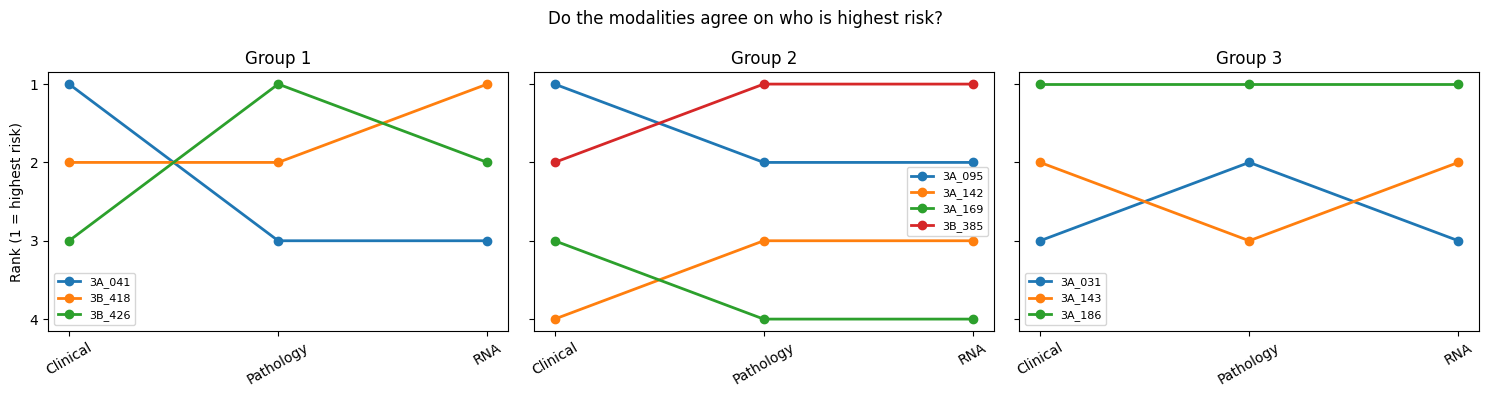

In [ ]:
#@title 1. Reveal the three unimodal rankings { display-mode: "form" }
display(ranking_table(["Clinical", "Pathology", "RNA"]))
rank_plot(["Clinical", "Pathology", "RNA"], "Do the modalities agree on who is highest risk?")

### Pause
Where lines cross, the modalities disagree about the same patients.
That disagreement is the fusion problem: a modality can be complementary, redundant, noisy, or contradictory.

# Step 2 — Fusion

> 🎯 **Goal of this step:** see that combining modalities changes the ranking, and that the fused model does not simply follow the strongest modality or average them. Then look inside gated fusion: its per-patient scaling can be inspected, but it is not an importance score.

- **Concatenation:** the survival head sees all three embeddings, `z = [h_R; h_C; h_P]`.
- **Gated fusion:** each embedding is first multiplied by its own learned factor between 0 and 1,
  `z = [g_R h_R; g_C h_C; g_P h_P]`. Each factor is computed from that modality alone,
  the factors do not sum to 1, and they are **not** importance scores.

**Before running:** which modality do you expect the fused models to follow?

Clinical          Pathology           RNA          Concatenation  \
       Group     Rank × lowest      Rank × lowest Rank × lowest          Rank   
3A_041     1        1     2.09         3     1.00    3     1.00             3   
3B_418     1        2     1.59         2     1.38    1     2.54             1   
3B_426     1        3     1.00         1     2.01    2     2.20             2   
3A_095     2        1     2.43         2     2.45    2     2.70             1   
3A_142     2        4     1.00         3     1.61    3     2.00             3   
3A_169     2        3     1.11         4     1.00    4     1.00             4   
3B_385     2        2     1.58         1     5.41    1     2.74             2   
3A_031     3        3     1.00         2     1.02    3     1.00             2   
3A_143     3        2     1.23         3     1.00    2     1.10             3   
3A_186     3        1     3.08         1     1.05    1     2.38             1   

                Gated fusion           
       × lowest         Rank × lowest  
3A_041     1.00            3     1.00  
3B_418     4.21            1     4.53  
3B_426     3.00            2     2.54  
3A_095    34.24            1     5.77  
3A_142     3.44            3     1.49  
3A_169     1.00            4     1.00  
3B_385    12.40            2     3.98  
3A_031     1.11            2     1.27  
3A_143     1.00            3     1.00  
3A_186     5.89            1     7.28

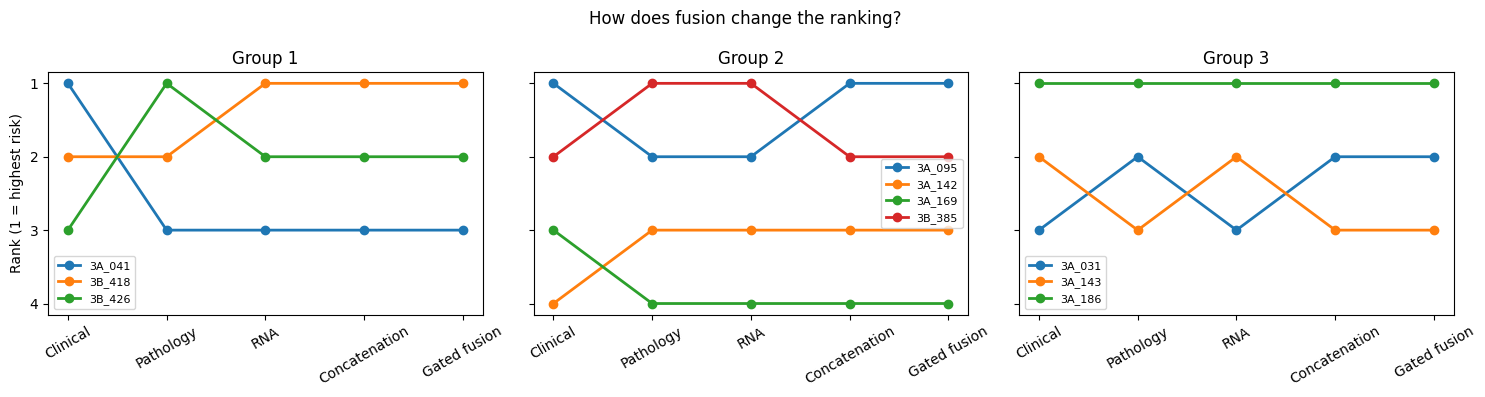

In [ ]:
#@title 2A. Reveal the fused rankings { display-mode: "form" }
FULL_DATA_MODELS = ["Clinical", "Pathology", "RNA", "Concat", "Gated"]
display(ranking_table(FULL_DATA_MODELS))
rank_plot(FULL_DATA_MODELS, "How does fusion change the ranking?")



# Step 3 — Reveal the outcomes, and score every model

> 🎯 **Goal of this step:** stop judging models by how convincing their ranking looks, and start judging them against what actually happened. This step also introduces the scoring method the rest of the tutorial reuses.

So far we have only compared models **to each other**. Now bring in the one thing that actually matters: what happened to these patients.

**How we score a model:** take every pair of patients scored by the same trained model. When one of them progressed before the other's follow-up ended, the model "wins" that pair if it gave the sooner-progressing patient the higher predicted risk. The score is correctly-ordered pairs out of every pair we can judge this way — a small, hands-on version of the concordance index (C-index) used to evaluate Cox models.

In [ ]:
#@title 3A. Reveal observed outcomes { display-mode: "form" }
OUTCOME = labels_by_case.loc[ALL_CASES].copy()
OUTCOME_LABEL = {
    c: f"{'Progressed' if OUTCOME.loc[c, 'Event'] == 1 else 'No progression'} at {OUTCOME.loc[c, 'Time']:.0f} mo"
    for c in ALL_CASES
}

display(pd.DataFrame({
    "Group": [CASES[c] for c in ALL_CASES],
    "Observed": [OUTCOME_LABEL[c] for c in ALL_CASES],
}, index=ALL_CASES))

def fmt_score(good, total):
    # "12 of 20 (60%)" — the one format used everywhere we report a score.
    pct = round(100 * good / total) if total else 0
    return f"{int(good)} of {int(total)} ({pct}%)"

def correctly_ordered(scores):
    # scores: Series of log-risk per patient. Only pairs within the same group are compared,
    # since only those patients were scored by the same trained model.
    good, total = 0, 0
    for i in ALL_CASES:
        for j in ALL_CASES:
            if CASES[i] != CASES[j]:
                continue
            if OUTCOME.loc[i, "Event"] == 1 and OUTCOME.loc[i, "Time"] < OUTCOME.loc[j, "Time"]:
                total += 1
                good += float(scores[i]) > float(scores[j])
    return good, total

def scoreboard(model_scores, title):
    # model_scores: dict label -> (correct, total). Shows a sorted table + bar chart, best on top.
    rows = [{"Model": label, "Correct": g, "Total": t, "Frac": (g / t if t else float("nan"))}
            for label, (g, t) in model_scores.items()]
    board = pd.DataFrame(rows).sort_values("Frac", ascending=False, kind="stable").reset_index(drop=True)

    shown = board.copy()
    shown["Pairs ordered correctly"] = [fmt_score(g, t) for g, t in zip(board["Correct"], board["Total"])]
    display(shown.set_index("Model")[["Pairs ordered correctly"]])

    top = board["Frac"].max()
    colors = ["tab:red" if f == top else "lightgray" for f in board["Frac"]]
    plt.figure(figsize=(7.5, 0.55 * len(board) + 1.5))
    plt.barh(board["Model"][::-1], (board["Frac"] * 100)[::-1], color=colors[::-1])
    plt.xlim(0, 100)
    plt.xlabel("Pairs ordered correctly (%)")
    plt.title(title)
    plt.tight_layout()
    plt.show()

    winners = board.loc[board["Frac"] == top, "Model"].tolist()
    best = fmt_score(board.iloc[0]["Correct"], board.iloc[0]["Total"])
    if len(winners) == 1:
        print(f"Best on these patients: {winners[0]} — {best}")
    else:
        print(f"Tied for best on these patients: {', '.join(winners)} — {best}")
    return board

,Group,Observed
3A_041,1,Progressed at 10 mo
3B_418,1,Progressed at 12 mo
3B_426,1,Progressed at 5 mo
3A_095,2,Progressed at 6 mo
3A_142,2,No progression at 202 mo
3A_169,2,No progression at 155 mo
3B_385,2,No progression at 104 mo
3A_031,3,No progression at 119 mo
3A_143,3,No progression at 119 mo
3A_186,3,Progressed at 14 mo


**Before running:** rank the five models — Clinical, Pathology, RNA, Concatenation, Gated fusion — from best to worst at matching these outcomes. Then check.

With only 10 patients, treat the score below as a demonstration of *how* to compare models, not a final verdict — the real answer needs the full validation cohort.

In [ ]:
#@title 3B. Which model matches the outcomes best? { display-mode: "form" }
model_scores = {MODEL_LABELS[k]: correctly_ordered(RAW_RISK[k]) for k in FULL_DATA_MODELS}
_ = scoreboard(model_scores, "Which model ordered patients the way things turned out?")

NameError: name 'FULL_DATA_MODELS' is not defined

# Step 4 — What if RNA is missing?

> 🎯 **Goal of this step:** evaluate a multimodal model under the data you will really have at deployment. Robustness to a missing modality comes from how the model is trained (how often it saw RNA missing), not from gating, and what matters is whether the ordering still matches the outcomes, not only how much the numbers move.

RNA-seq is often not available at deployment. Now that we know the outcomes, we can ask the question that matters:

> **Without RNA, does the model still order the patients the way things turned out?**

This step uses **different fusion models** from Step 2: versions trained with RNA hidden for **30%** or for **50%** of the training patients, so they have seen missing RNA before.
That is why the "with RNA" results differ slightly from Step 2. Without RNA, all of them set the RNA embedding to zero and predict from clinical + pathology only.

**Before running:** do you expect the 50%-trained models to hold up better without RNA than the 30%-trained ones? What might that cost when RNA *is* available?

In [ ]:
#@title 4A. Does the ordering still match the outcomes without RNA? { display-mode: "form" }
DROPOUT_SCORES = {}
for setup in DROPOUT_SETUPS:
    for method in ["Concat", "Gated"]:
        sub = MISSINGNESS[(MISSINGNESS["Dropout"] == setup) & (MISSINGNESS["Fusion"] == method)]
        sub = sub.set_index("Patient").loc[ALL_CASES]
        DROPOUT_SCORES[(setup, method, "with")] = sub["Complete RNA"].astype(float)
        DROPOUT_SCORES[(setup, method, "without")] = sub["RNA missing"].astype(float)

rows = []
for setup in DROPOUT_SETUPS:
    for method in ["Concat", "Gated"]:
        g1, t1 = correctly_ordered(DROPOUT_SCORES[(setup, method, "with")])
        g0, t0 = correctly_ordered(DROPOUT_SCORES[(setup, method, "without")])
        rows.append({
            "RNA hidden in training": setup,
            "Fusion": MODEL_LABELS[method],
            "Correct pairs WITH RNA": fmt_score(g1, t1),
            "Correct pairs WITHOUT RNA": fmt_score(g0, t0),
        })
display(pd.DataFrame(rows).set_index(["RNA hidden in training", "Fusion"]))

Correct pairs WITH RNA  \
RNA hidden in training Fusion                                 
30%                    Concatenation           6 of 8 (75%)   
                       Gated fusion            5 of 8 (62%)   
50%                    Concatenation           5 of 8 (62%)   
                       Gated fusion            5 of 8 (62%)   

                                     Correct pairs WITHOUT RNA  
RNA hidden in training Fusion                                   
30%                    Concatenation              6 of 8 (75%)  
                       Gated fusion               5 of 8 (62%)  
50%                    Concatenation              6 of 8 (75%)  
                       Gated fusion               5 of 8 (62%)

,Group,Observed,30% · Concatenation: rank with → without,30% · Gated fusion: rank with → without,50% · Concatenation: rank with → without,50% · Gated fusion: rank with → without
3A_041,1,Progressed at 10 mo,3 → 1 ◀ changed,2 → 1 ◀ changed,1 → 1,1 → 1
3B_418,1,Progressed at 12 mo,1 → 3 ◀ changed,1 → 2 ◀ changed,2 → 2,2 → 2
3B_426,1,Progressed at 5 mo,2 → 2,3 → 3,3 → 3,3 → 3
3A_095,2,Progressed at 6 mo,1 → 2 ◀ changed,1 → 2 ◀ changed,2 → 1 ◀ changed,2 → 2
3A_142,2,No progression at 202 mo,4 → 4,4 → 4,4 → 4,3 → 3
3A_169,2,No progression at 155 mo,3 → 3,3 → 3,3 → 3,4 → 4
3B_385,2,No progression at 104 mo,2 → 1 ◀ changed,2 → 1 ◀ changed,1 → 2 ◀ changed,1 → 1
3A_031,3,No progression at 119 mo,3 → 2 ◀ changed,3 → 2 ◀ changed,2 → 2,2 → 2
3A_143,3,No progression at 119 mo,2 → 3 ◀ changed,2 → 3 ◀ changed,3 → 3,3 → 3
3A_186,3,Progressed at 14 mo,1 → 1,1 → 1,1 → 1,1 → 1


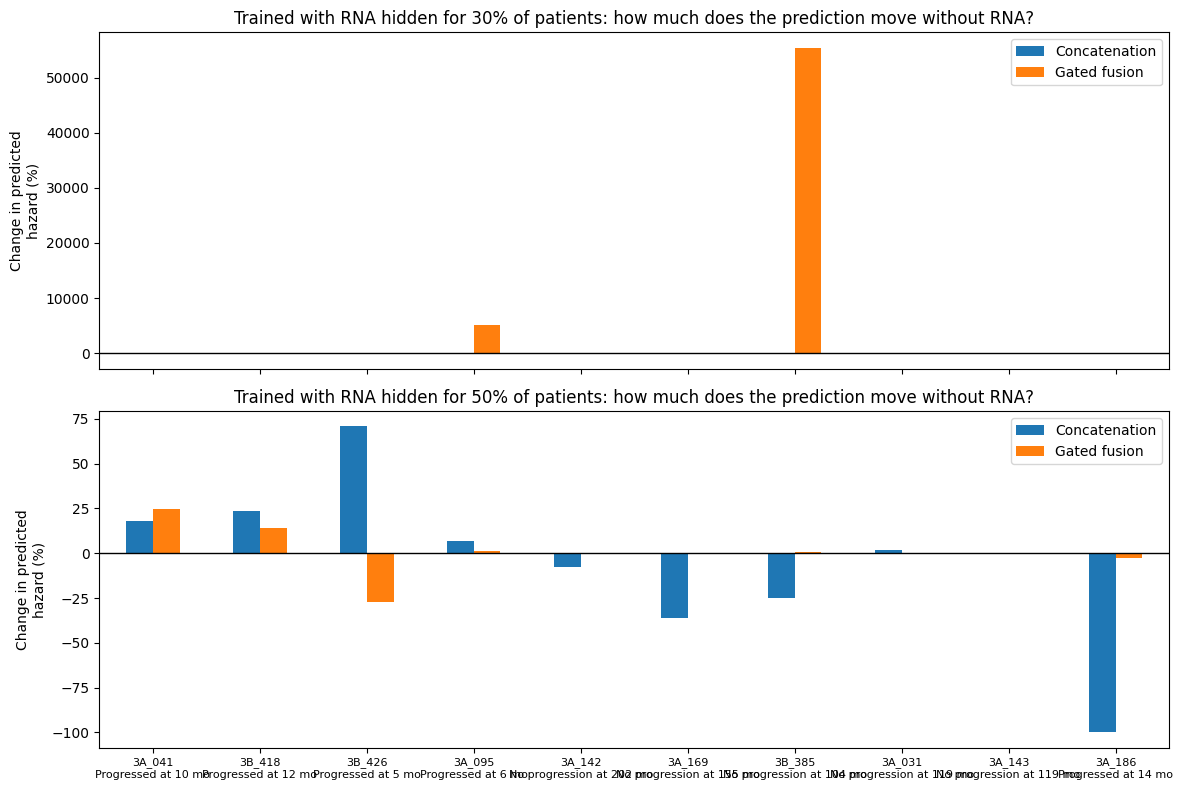

In [ ]:
#@title 4B. Patient by patient { display-mode: "form" }
table = pd.DataFrame({"Group": [CASES[c] for c in ALL_CASES],
                      "Observed": [OUTCOME_LABEL[c] for c in ALL_CASES]}, index=ALL_CASES)
for setup in DROPOUT_SETUPS:
    for method in ["Concat", "Gated"]:
        w = within_group_rank(DROPOUT_SCORES[(setup, method, "with")])
        wo = within_group_rank(DROPOUT_SCORES[(setup, method, "without")])
        table[f"{setup} · {MODEL_LABELS[method]}: rank with → without"] = [
            f"{w[c]} → {wo[c]}" + ("  ◀ changed" if w[c] != wo[c] else "") for c in ALL_CASES
        ]
display(table)

fig, axes = plt.subplots(len(DROPOUT_SETUPS), 1, figsize=(12, 4 * len(DROPOUT_SETUPS)), sharex=True, squeeze=False)
for ax, setup in zip(axes[:, 0], DROPOUT_SETUPS):
    pct = pd.DataFrame({
        MODEL_LABELS[m]: 100 * (np.exp(DROPOUT_SCORES[(setup, m, "without")] - DROPOUT_SCORES[(setup, m, "with")]) - 1)
        for m in ["Concat", "Gated"]
    })
    pct.index = [f"{c}\n{OUTCOME_LABEL[c]}" for c in ALL_CASES]
    pct.plot(kind="bar", ax=ax)
    ax.axhline(0, linewidth=1, color="black")
    ax.set_ylabel("Change in predicted\nhazard (%)")
    ax.set_title(f"Trained with RNA hidden for {setup} of patients: how much does the prediction move without RNA?")
axes[-1, 0].tick_params(axis="x", rotation=0, labelsize=8)
plt.tight_layout()
plt.show()

### How to read this
- **4A** is the key result: if the number of correctly ordered pairs barely drops without RNA, the model is robust *for these patients*.
  Compare the 30% and 50% rows: does seeing more missing RNA in training make the model more robust, and does it cost anything when RNA *is* available?
- **4B** shows who moved. A patient whose risk goes up without RNA had RNA pulling their risk down, and vice versa.
  Look at the outcome next to them: did losing RNA move them in the right or the wrong direction?

### A note on gated fusion without RNA
The RNA factor is **set to 0 by design** when RNA is missing; the model does not learn to switch RNA off.
The clinical and pathology factors are computed from their own embeddings only, so they are **identical** with and without RNA.
Gated fusion therefore cannot shift weight towards pathology to make up for the missing RNA:
any difference in robustness between the two models comes from **training with RNA dropout**, not from the gates reacting.

### Discuss
1. Does removing RNA cost correctly ordered pairs? For which model?
2. Do the 50%-trained models move less than the 30%-trained ones when RNA is removed? What is the trade-off?
3. For the patients who moved, did losing RNA push them towards or away from their observed outcome?
4. What would happen with a model that never saw missing RNA during training?
5. What design would let a model re-weight the remaining modalities when one is missing?

# Putting it all together

> 🎯 **Goal:** one final scoreboard — every modality, every fusion method, with and without RNA — scored the exact same way, side by side.

,Pairs ordered correctly
Model,
Clinical,6 of 8 (75%)
Pathology,6 of 8 (75%)
Concatenation,6 of 8 (75%)
Gated fusion,6 of 8 (75%)
Concatenation · 30% dropout · with RNA,6 of 8 (75%)
Concatenation · 30% dropout · without RNA,6 of 8 (75%)
Concatenation · 50% dropout · without RNA,6 of 8 (75%)
RNA,5 of 8 (62%)
Gated fusion · 30% dropout · with RNA,5 of 8 (62%)


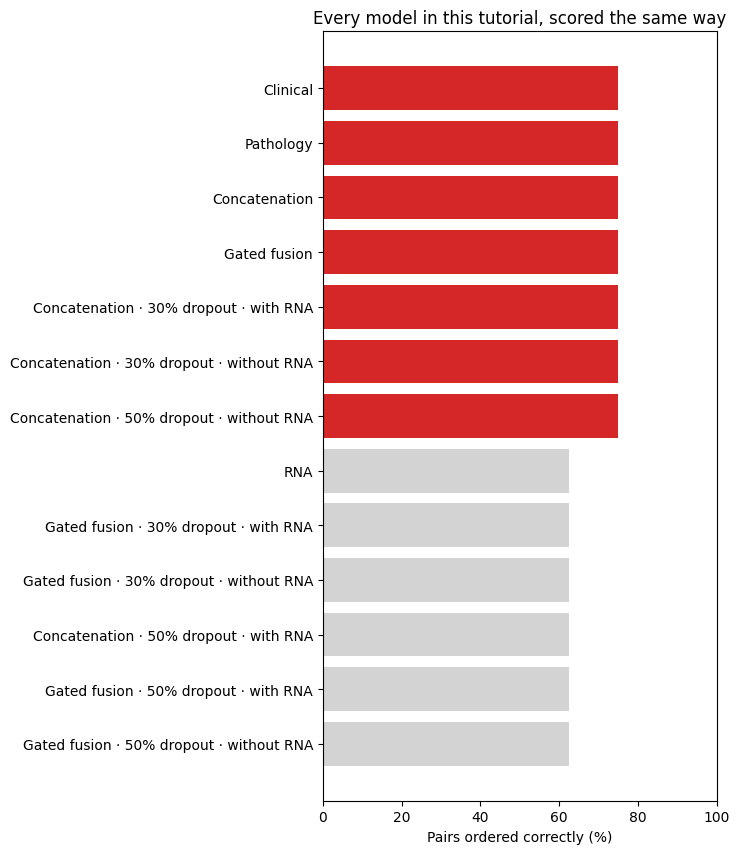

Tied for best on these patients: Clinical, Pathology, Concatenation, Gated fusion, Concatenation · 30% dropout · with RNA, Concatenation · 30% dropout · without RNA, Concatenation · 50% dropout · without RNA — 6 of 8 (75%)


In [ ]:
#@title Putting it all together { display-mode: "form" }
final_scores = {MODEL_LABELS[k]: correctly_ordered(RAW_RISK[k]) for k in FULL_DATA_MODELS}
for setup in DROPOUT_SETUPS:
    for method in ["Concat", "Gated"]:
        for cond, cond_label in [("with", "with RNA"), ("without", "without RNA")]:
            key = f"{MODEL_LABELS[method]} · {setup} dropout · {cond_label}"
            final_scores[key] = correctly_ordered(DROPOUT_SCORES[(setup, method, cond)])
_ = scoreboard(final_scores, "Every model in this tutorial, scored the same way")

"Concatenation" and "Gated fusion" here are the standard-trained models from Step 2; the dropout-trained variants are separate checkpoints, trained to expect missing RNA.

**Reflect:** does any single approach win under every condition here (full data, 30% dropout, 50% dropout)? What does that tell you about calling one architecture "the best"?

### Take-home
1. Start unimodal: do the modalities agree on who is highest risk?
2. A Cox model ranks patients; compare predicted hazards within the same model, not raw scores across models.
3. Concatenation is the simple reference; gating adds per-patient scaling you can inspect.
4. Scaling factors describe model behaviour, not importance or biology.
5. Evaluate under the data you will have at deployment, including missing RNA.
6. "Better" is decided by counting correctly ordered pairs against outcomes — on a real cohort, not ten patients. You now know exactly how to run that check yourself.